# Sales Effectiveness — Exploratory Data Analysis (EDA)

**Client project:** DataMites Sales Effectiveness (PR-0019)  
**Task 1:** Data exploration insights — Sales effectiveness

### Objective
Explore the available sales-lead data, check data quality, understand lead statuses and compare leads across sources, sales agents, locations and delivery modes.

**Dataset:** `sales_effectiveness.csv`  
Keep this CSV file in the same folder as this notebook before running the notebook.

> This notebook performs EDA only. The project brief's desired prediction categories are *High Potential* and *Low Potential*, but the provided `Status` values contain several operational statuses. We should confirm the business rule for mapping these statuses before creating a machine-learning target.


## 1. Import the libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load the dataset

In [ ]:
# Keep sales_effectiveness.csv in the same folder as this notebook.
df = pd.read_csv("sales_effectiveness.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head())


## 3. Understand the dataset structure

In [ ]:
# Column names
print("Column names:")
print(df.columns.tolist())

# Data types and non-missing counts
df.info()

# Summary of numeric and categorical columns
display(df.describe(include="all").T)


## 4. Check missing values

In [ ]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
}).sort_values("Missing Count", ascending=False)

display(missing_summary)


## 5. Check duplicate records

In [ ]:
duplicate_count = df.duplicated().sum()
print("Number of completely duplicated rows:", duplicate_count)

# Inspect duplicates first; do not remove them automatically.
display(df[df.duplicated(keep=False)].head(10))


## 6. Explore lead status

In [ ]:
status_counts = df["Status"].value_counts(dropna=False)
display(status_counts.rename_axis("Status").reset_index(name="Lead Count"))

plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="Status", order=df["Status"].value_counts().index)
plt.title("Number of Leads by Status")
plt.xlabel("Number of Leads")
plt.ylabel("Status")
plt.tight_layout()
plt.show()


### Note about status labels
The dataset contains both `CONVERTED` and `converted`. These may represent the same business outcome with different capitalization. For EDA, the notebook shows the original values; do not merge categories or define High/Low Potential until the project mentor confirms the intended mapping.


## 7. Explore lead source

In [ ]:
source_counts = df["Source"].fillna("Missing").value_counts()
display(source_counts.rename_axis("Source").reset_index(name="Lead Count").head(20))

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y="Source", order=df["Source"].value_counts().index)
plt.title("Number of Leads by Source")
plt.xlabel("Number of Leads")
plt.ylabel("Source")
plt.tight_layout()
plt.show()


## 8. Explore sales agents

In [ ]:
agent_counts = df["Sales_Agent"].fillna("Missing").value_counts()
display(agent_counts.rename_axis("Sales Agent").reset_index(name="Lead Count"))

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y="Sales_Agent", order=df["Sales_Agent"].value_counts().index)
plt.title("Number of Leads Assigned to Each Sales Agent")
plt.xlabel("Number of Leads")
plt.ylabel("Sales Agent")
plt.tight_layout()
plt.show()


## 9. Explore location and delivery mode

In [ ]:
print("Leads by location (top 15):")
display(df["Location"].fillna("Missing").value_counts().head(15).rename_axis("Location").reset_index(name="Lead Count"))

print("Leads by delivery mode:")
display(df["Delivery_Mode"].fillna("Missing").value_counts().rename_axis("Delivery Mode").reset_index(name="Lead Count"))

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Delivery_Mode", order=df["Delivery_Mode"].value_counts().index)
plt.title("Number of Leads by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Number of Leads")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 10. Explore lead creation dates

In [ ]:
# Convert Created to datetime. The source format appears to be day-month-year.
df["Created_Date"] = pd.to_datetime(
    df["Created"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

print("Dates that could not be parsed:", df["Created_Date"].isna().sum())

# Count leads by date
leads_by_date = df.dropna(subset=["Created_Date"]).groupby(
    df["Created_Date"].dt.date
).size()

plt.figure(figsize=(12, 4))
leads_by_date.plot()
plt.title("Number of Leads Created Over Time")
plt.xlabel("Created Date")
plt.ylabel("Number of Leads")
plt.tight_layout()
plt.show()


## 11. Compare status with source and sales agent

In [ ]:
# Counts of each status by source
status_by_source = pd.crosstab(df["Source"].fillna("Missing"), df["Status"])
display(status_by_source)

# Counts of each status by sales agent
status_by_agent = pd.crosstab(df["Sales_Agent"].fillna("Missing"), df["Status"])
display(status_by_agent)


## 12. Check the main findings

In [ ]:
print("EDA summary")
print("- Rows:", len(df))
print("- Columns:", len(df.columns) - 1, "(original columns; Created_Date was added for analysis)")
print("- Completely duplicated rows:", df.duplicated(subset=df.columns.drop("Created_Date", errors="ignore")).sum() if "Created_Date" in df.columns else df.duplicated().sum())
print("- Most common status:", df["Status"].value_counts().idxmax())
print("- Most common source:", df["Source"].mode(dropna=True).iloc[0] if df["Source"].notna().any() else "No non-missing values")
print("- Sales agents recorded:", df["Sales_Agent"].nunique(dropna=True))
print("- Locations recorded:", df["Location"].nunique(dropna=True))
print("- Delivery modes recorded:", df["Delivery_Mode"].nunique(dropna=True))

print("\nMissing values by column:")
display(df.isnull().sum().rename("Missing Count").to_frame())


## 13. Business observations and conclusion

After running the notebook, use the tables and charts above to describe:
1. Which lead statuses occur most frequently.
2. Which lead sources generate the most leads.
3. How lead assignments vary across sales agents.
4. Which locations and delivery modes appear most often.
5. Whether lead creation volume changes over time.
6. Which columns contain missing values or duplicate rows and may need attention.

### Important limitations
- This is an observational EDA; lead counts alone do not prove that a source or sales agent is more effective.
- `Mobile` and `EMAIL` are contact fields. They are not needed for the initial charts and should not be displayed or shared unnecessarily.
- `Status` contains multiple categories, including differently capitalized `CONVERTED` and `converted`. Confirm how these should be treated.
- The project brief requests a High Potential / Low Potential prediction model, but this CSV's `Status` categories do not directly provide those two labels. Confirm the target-label definition before model training.

**Conclusion:** This notebook completes the first stage of the project by examining the structure, quality and patterns of the sales-lead dataset. Use the observed outputs to write final business insights after running the cells.


## 14. Import modelling libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score
)

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.7.2


## 15. Load and validate the modelling data

In [3]:
df_model = pd.read_csv("sales_effectiveness.csv")

required_columns = [
    "Created", "Product_ID", "Source", "Mobile", "EMAIL",
    "Sales_Agent", "Location", "Delivery_Mode", "Status"
]
missing_columns = sorted(set(required_columns) - set(df_model.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

print("Dataset shape:", df_model.shape)
print("\nStatus values and counts (review before target mapping):")
display(
    df_model["Status"].fillna("<MISSING>")
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Count")
)

Dataset shape: (7422, 9)

Status values and counts (review before target mapping):


,Status,Count
0,Junk Lead,1536
1,Not Responding,1129
2,CONVERTED,834
3,Just Enquiry,760
4,Potential,708
5,Long Term,646
6,In Progress Positive,643
7,In Progress Negative,626
8,LOST,440
9,Open,82


## 16. Create the target variable

In [10]:
# Map existing Status values to Lead_Category


status_mapping = {
    'CONVERTED': 'High Potential',
    'converted': 'High Potential',
    'Potential': 'High Potential',
    'In Progress Positive': 'High Potential',

    'Junk Lead': 'Low Potential',
    'Not Responding': 'Low Potential',
    'Just Enquiry': 'Low Potential',
    'Long Term': 'Low Potential',
    'In Progress Negative': 'Low Potential',
    'LOST': 'Low Potential',
    'Open': 'Low Potential'
}

# Create target column
df_model['Lead_Category'] = df_model['Status'].map(status_mapping)

# Check for missing target labels
print("Missing target labels:", df_model['Lead_Category'].isna().sum())

# Display target distribution
print("\nLead Category Counts:")
display(df_model['Lead_Category'].value_counts())

print("\nLead Category Percentages:")
display(
    (df_model['Lead_Category'].value_counts(normalize=True) * 100)
    .round(2)
)

Missing target labels: 0

Lead Category Counts:


Lead_Category
Low Potential     5219
High Potential    2203
Name: count, dtype: int64


Lead Category Percentages:


Lead_Category
Low Potential     70.32
High Potential    29.68
Name: proportion, dtype: float64

## 17.Feature Engineering

In [9]:
import pandas as pd

# Convert Created column into datetime
df_model['Created_Date'] = pd.to_datetime(
    df_model['Created'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

# Extract useful date features
df_model['Created_Year'] = df_model['Created_Date'].dt.year
df_model['Created_Month'] = df_model['Created_Date'].dt.month
df_model['Created_DayOfWeek'] = df_model['Created_Date'].dt.dayofweek
df_model['Created_Hour'] = df_model['Created_Date'].dt.hour

# Check for invalid date conversions
print("Invalid Dates:", df_model['Created_Date'].isna().sum())

# Display engineered features
display(
    df_model[
        [
            'Created',
            'Created_Year',
            'Created_Month',
            'Created_DayOfWeek',
            'Created_Hour',
            'Lead_Category'
        ]
    ].head(10)
)

Invalid Dates: 0


,Created,Created_Year,Created_Month,Created_DayOfWeek,Created_Hour,Lead_Category
0,14-11-2018 10:05,2018,11,2,10,Low Potential
1,14-11-2018 09:22,2018,11,2,9,Low Potential
2,14-11-2018 09:21,2018,11,2,9,Low Potential
3,14-11-2018 08:46,2018,11,2,8,Low Potential
4,14-11-2018 07:34,2018,11,2,7,Low Potential
5,14-11-2018 07:33,2018,11,2,7,Low Potential
6,14-11-2018 05:58,2018,11,2,5,Low Potential
7,14-11-2018 05:49,2018,11,2,5,Low Potential
8,14-11-2018 05:40,2018,11,2,5,Low Potential
9,14-11-2018 05:06,2018,11,2,5,Low Potential


## 18. Select features (X) and target (y)

In [8]:
# Target variable
y = df_model['Lead_Category']

# Input features
feature_columns = [
    'Product_ID',
    'Source',
    'Sales_Agent',
    'Location',
    'Delivery_Mode',
    'Created_Year',
    'Created_Month',
    'Created_DayOfWeek',
    'Created_Hour'
]

X = df_model[feature_columns].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values in features:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7422, 9)
Target shape: (7422,)

Feature columns:
['Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Year', 'Created_Month', 'Created_DayOfWeek', 'Created_Hour']

Missing values in features:
Product_ID           58
Source               17
Sales_Agent          23
Location             58
Delivery_Mode         0
Created_Year          0
Created_Month         0
Created_DayOfWeek     0
Created_Hour          0
dtype: int64

Target distribution:
Lead_Category
Low Potential     5219
High Potential    2203
Name: count, dtype: int64


## 19. Handle Missing Values and Encode Categorical Features

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define numerical and categorical features
numeric_features = [
    'Created_Year',
    'Created_Month',
    'Created_DayOfWeek',
    'Created_Hour'
]

categorical_features = [
    'Product_ID',
    'Source',
    'Sales_Agent',
    'Location',
    'Delivery_Mode'
]

# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully.")

Numerical features: ['Created_Year', 'Created_Month', 'Created_DayOfWeek', 'Created_Hour']
Categorical features: ['Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode']

Preprocessing pipeline created successfully.


## 20. Split Data into Training and Testing Sets

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features shape: (5937, 9)
Testing features shape: (1485, 9)

Training target shape: (5937,)
Testing target shape: (1485,)

Training target distribution:
Lead_Category
Low Potential     4175
High Potential    1762
Name: count, dtype: int64

Testing target distribution:
Lead_Category
Low Potential     1044
High Potential     441
Name: count, dtype: int64


## 21. Train the Logistic Regression Model

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the model pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")
print("Number of training records:", len(X_train))
print("Number of predictions:", len(y_pred_logistic))

print("\nFirst 10 predictions:")
print(y_pred_logistic[:10])

Logistic Regression model trained successfully!
Number of training records: 5937
Number of predictions: 1485

First 10 predictions:
['High Potential' 'Low Potential' 'Low Potential' 'High Potential'
 'Low Potential' 'Low Potential' 'High Potential' 'Low Potential'
 'High Potential' 'High Potential']


## 22. Evaluate the Logistic Regression Model

Logistic Regression Evaluation Results
----------------------------------------
Accuracy:  0.7017
Precision: 0.4985
Recall:    0.7483
F1-Score:  0.5984

Classification Report:
                precision    recall  f1-score   support

High Potential       0.50      0.75      0.60       441
 Low Potential       0.87      0.68      0.76      1044

      accuracy                           0.70      1485
     macro avg       0.68      0.72      0.68      1485
  weighted avg       0.76      0.70      0.71      1485



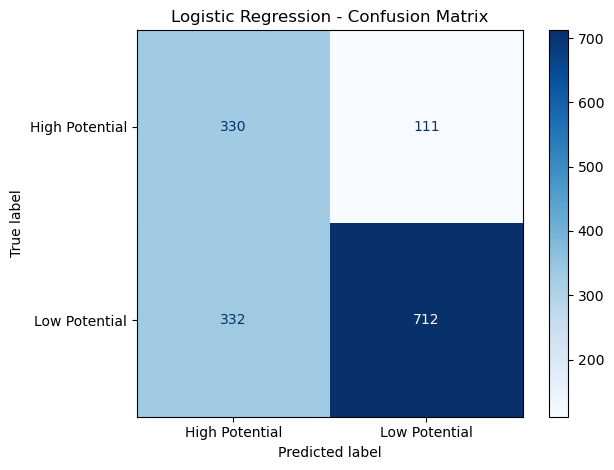

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_logistic)

precision = precision_score(
    y_test, y_pred_logistic,
    pos_label='High Potential'
)

recall = recall_score(
    y_test, y_pred_logistic,
    pos_label='High Potential'
)

f1 = f1_score(
    y_test, y_pred_logistic,
    pos_label='High Potential'
)

print("Logistic Regression Evaluation Results")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

# Confusion matrix with explicit class order
labels = ['High Potential', 'Low Potential']

cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Logistic Regression - Confusion Matrix')
plt.tight_layout()
plt.show()

## 23. Logistic Regression — Results Analysis

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")
print("Training records:", len(X_train))
print("Predictions generated:", len(y_pred_rf))

print("\nFirst 10 predictions:")
print(y_pred_rf[:10])

Random Forest model trained successfully!
Training records: 5937
Predictions generated: 1485

First 10 predictions:
['High Potential' 'Low Potential' 'Low Potential' 'High Potential'
 'Low Potential' 'Low Potential' 'High Potential' 'Low Potential'
 'High Potential' 'High Potential']


## 24. Evaluate the Random Forest Model

Random Forest Evaluation Results
----------------------------------------
Accuracy:  0.7313
Precision: 0.5372
Recall:    0.6871
F1-Score:  0.6030

Classification Report:
                precision    recall  f1-score   support

High Potential       0.54      0.69      0.60       441
 Low Potential       0.85      0.75      0.80      1044

      accuracy                           0.73      1485
     macro avg       0.69      0.72      0.70      1485
  weighted avg       0.76      0.73      0.74      1485



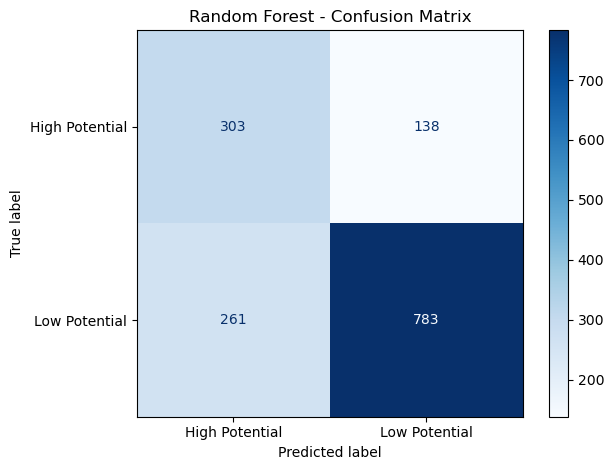

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test, y_pred_rf,
    pos_label='High Potential'
)

recall_rf = recall_score(
    y_test, y_pred_rf,
    pos_label='High Potential'
)

f1_rf = f1_score(
    y_test, y_pred_rf,
    pos_label='High Potential'
)

print("Random Forest Evaluation Results")
print("-" * 40)
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion matrix
labels = ['High Potential', 'Low Potential']

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=labels
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()

## 25. Train the Gradient Boosting Model

In [18]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Create the Gradient Boosting pipeline
gradient_boosting_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Generate predictions
y_pred_gb = gradient_boosting_model.predict(X_test)

print("Gradient Boosting model trained successfully!")
print("Training records:", len(X_train))
print("Predictions generated:", len(y_pred_gb))

print("\nFirst 10 predictions:")
print(y_pred_gb[:10])

Gradient Boosting model trained successfully!
Training records: 5937
Predictions generated: 1485

First 10 predictions:
['High Potential' 'Low Potential' 'Low Potential' 'Low Potential'
 'Low Potential' 'Low Potential' 'High Potential' 'Low Potential'
 'High Potential' 'High Potential']


## 26. Evaluate the Gradient Boosting Model

Gradient Boosting Evaluation Results
----------------------------------------
Accuracy:  0.7710
Precision: 0.6996
Recall:    0.4014
F1-Score:  0.5101

Classification Report:
                precision    recall  f1-score   support

High Potential       0.70      0.40      0.51       441
 Low Potential       0.79      0.93      0.85      1044

      accuracy                           0.77      1485
     macro avg       0.74      0.66      0.68      1485
  weighted avg       0.76      0.77      0.75      1485



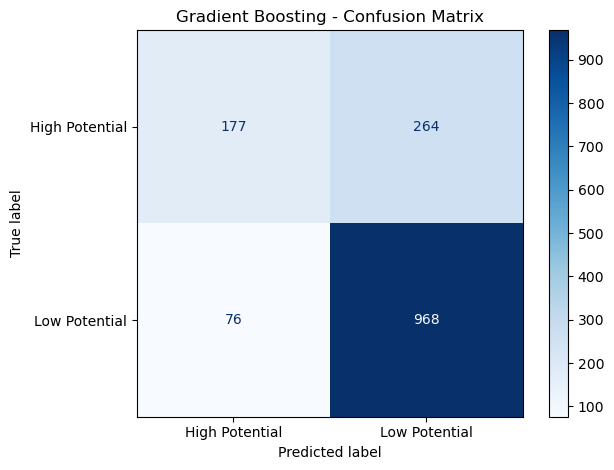

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy_gb = accuracy_score(y_test, y_pred_gb)

precision_gb = precision_score(
    y_test, y_pred_gb,
    pos_label='High Potential'
)

recall_gb = recall_score(
    y_test, y_pred_gb,
    pos_label='High Potential'
)

f1_gb = f1_score(
    y_test, y_pred_gb,
    pos_label='High Potential'
)

print("Gradient Boosting Evaluation Results")
print("-" * 40)
print(f"Accuracy:  {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall:    {recall_gb:.4f}")
print(f"F1-Score:  {f1_gb:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

# Confusion matrix
labels = ['High Potential', 'Low Potential']

cm_gb = confusion_matrix(
    y_test,
    y_pred_gb,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=labels
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Gradient Boosting - Confusion Matrix')
plt.tight_layout()
plt.show()

## 27. Create the Final Model Comparison Table

Final Model Comparison:


,Model,Accuracy,High Potential Precision,High Potential Recall,High Potential F1-Score
0,Logistic Regression,0.7017,0.4985,0.7483,0.5984
1,Random Forest,0.7313,0.5372,0.6871,0.6030
2,Gradient Boosting,0.7710,0.6996,0.4014,0.5101


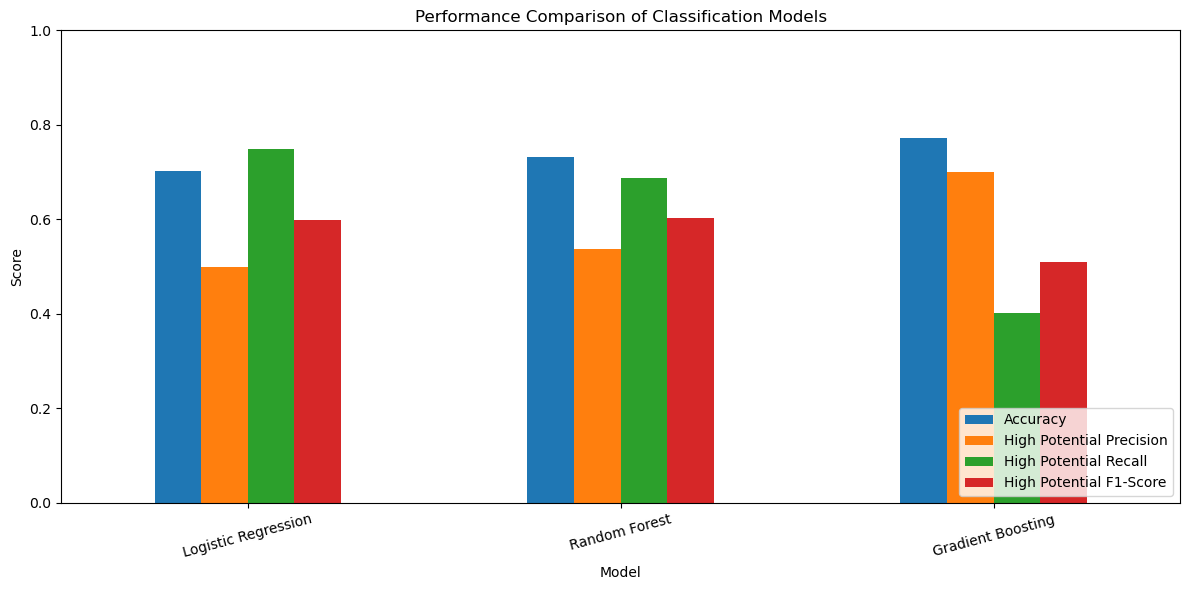

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy,
        accuracy_rf,
        accuracy_gb
    ],
    'High Potential Precision': [
        precision,
        precision_rf,
        precision_gb
    ],
    'High Potential Recall': [
        recall,
        recall_rf,
        recall_gb
    ],
    'High Potential F1-Score': [
        f1,
        f1_rf,
        f1_gb
    ]
})

print("Final Model Comparison:")
display(comparison_df.round(4))

# Compare the evaluation metrics visually
comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Classification Models')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 28. Examine Feature Importance

Top 15 Important Features:


,Feature,Importance
18,cat__Product_ID_15.0,0.129820
1,num__Created_Month,0.093184
79,cat__Location_Other Locations,0.086393
3,num__Created_Hour,0.063348
68,cat__Sales_Agent_Sales-Agent-9,0.053518
70,cat__Location_Bangalore,0.051418
2,num__Created_DayOfWeek,0.047124
90,cat__Delivery_Mode_Mode-5,0.042992
36,cat__Source_Customer Referral,0.034557
22,cat__Product_ID_19.0,0.029584


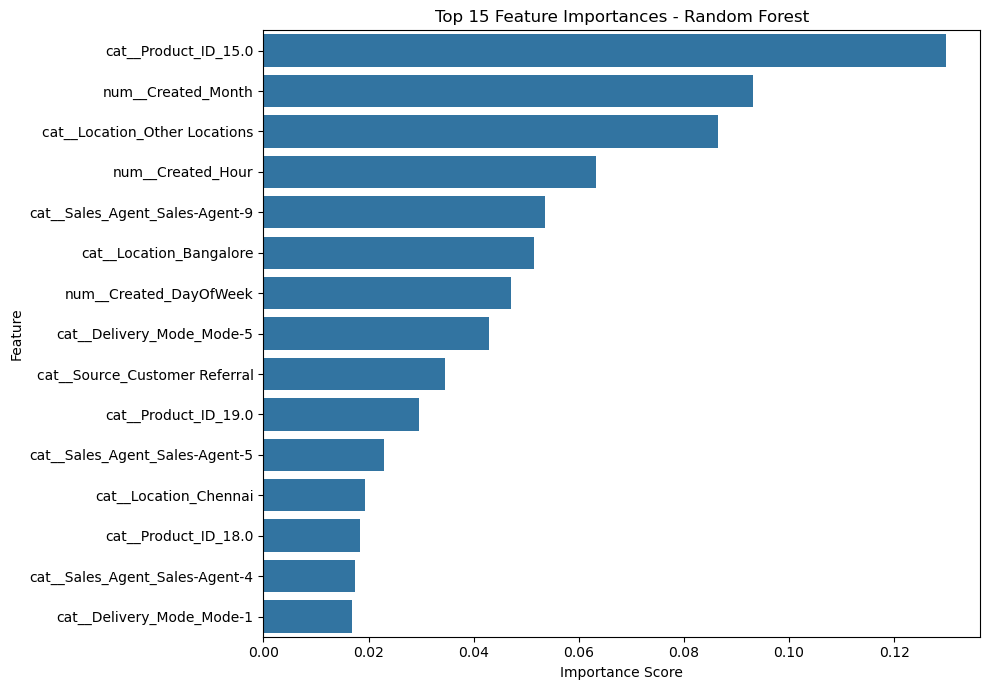

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the trained Random Forest classifier
rf_classifier = random_forest_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = (
    random_forest_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

# Extract feature importance scores
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

# Sort and display top 15 features
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))

# Plot top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 29. Save the Trained Random Forest Model

In [22]:
import joblib

# Save the complete pipeline, including preprocessing
joblib.dump(
    random_forest_model,
    'sales_effectiveness_random_forest.pkl'
)

print("Random Forest model saved successfully!")
print("File name: sales_effectiveness_random_forest.pkl")

Random Forest model saved successfully!
File name: sales_effectiveness_random_forest.pkl


## 30. Reload the Saved Model and Verify Predictions

In [23]:
import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load(
    'sales_effectiveness_random_forest.pkl'
)

# Generate predictions using the loaded model
y_pred_loaded = loaded_model.predict(X_test)

# Verify predictions match the original model
predictions_match = np.array_equal(y_pred_rf, y_pred_loaded)

print("Saved model loaded successfully!")
print("Total test records:", len(X_test))
print("Predictions match original model:", predictions_match)

print("\nSample predictions:")
print(y_pred_loaded[:10])

if predictions_match:
    print("\nModel verification PASSED!")
else:
    print("\nModel verification FAILED!")

Saved model loaded successfully!
Total test records: 1485
Predictions match original model: True

Sample predictions:
['High Potential' 'Low Potential' 'Low Potential' 'High Potential'
 'Low Potential' 'Low Potential' 'High Potential' 'Low Potential'
 'High Potential' 'High Potential']

Model verification PASSED!


## 31. Predict the Category of a New Lead

In [24]:
import pandas as pd

# Create sample lead data
new_lead = pd.DataFrame([{
    'Product_ID': 15.0,
    'Source': 'Customer Referral',
    'Sales_Agent': 'Sales-Agent-9',
    'Location': 'Bangalore',
    'Delivery_Mode': 'Mode-5',
    'Created_Year': 2018,
    'Created_Month': 11,
    'Created_DayOfWeek': 2,
    'Created_Hour': 10
}])

# Ensure the feature order matches the training data
new_lead = new_lead[X_train.columns]

# Predict using the saved model
predicted_category = loaded_model.predict(new_lead)[0]

print("New Lead Details:")
display(new_lead)

print("Predicted Lead Category:", predicted_category)

# Display class probabilities
probabilities = loaded_model.predict_proba(new_lead)[0]

print("\nPrediction Probabilities:")
for label, probability in zip(
    loaded_model.classes_,
    probabilities
):
    print(f"{label}: {probability:.2%}")

New Lead Details:


,Product_ID,Source,Sales_Agent,Location,Delivery_Mode,Created_Year,Created_Month,Created_DayOfWeek,Created_Hour
0,15.0,Customer Referral,Sales-Agent-9,Bangalore,Mode-5,2018,11,2,10


Predicted Lead Category: High Potential

Prediction Probabilities:
High Potential: 52.23%
Low Potential: 47.77%


## 32. Final Project Summary and Conclusions

# Sales Effectiveness — Final Project Summary

## 1. Project Objective

The objective of this project is to use Machine Learning to classify sales leads into High Potential and Low Potential categories to support sales effectiveness at FicZon Inc.

## 2. Dataset Overview

- Total records: 7,422
- Original columns: 9
- Target variable: `Lead_Category`
- Input features used: 9
- Training records: 5,937
- Testing records: 1,485

## 3. Data Preparation

Exploratory Data Analysis was completed before model building. The `Created` column was converted into datetime format, and date-based features were extracted. Missing values in the input features were handled using imputation. Categorical features were encoded using One-Hot Encoding, and numerical features were scaled within the preprocessing pipeline.

The `Status` column was excluded from the input features because it was used to construct the target variable. The `Mobile` and `EMAIL` columns were also excluded.

## 4. Target Distribution

The working target mapping produced the following distribution:

- Low Potential: 5,219 records (70.32%)
- High Potential: 2,203 records (29.68%)

The mapping was assumed for this implementation because the project brief does not specify the exact mapping from `Status` to `Lead_Category`. Consequently, the findings depend on this assumption.

## 5. Model Performance

Three classification algorithms were trained and evaluated on the same test set.

| Model | Accuracy | High Potential Precision | High Potential Recall | High Potential F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 70.17% | 49.85% | 74.83% | 59.84% |
| Random Forest | 73.13% | 53.72% | 68.71% | 60.30% |
| Gradient Boosting | 77.10% | 69.96% | 40.14% | 51.01% |

Gradient Boosting achieved the highest accuracy, while Logistic Regression achieved the highest recall for High Potential leads. Random Forest achieved the highest F1-score for High Potential leads among the three models.

Random Forest was retained as the initial candidate model because of its balance between precision and recall for the High Potential class.

## 6. Feature Importance

The Random Forest feature-importance analysis identified Product ID 15, creation month, location, creation hour, and sales-agent categories among the leading individual features.

These importance scores describe how the model used features and do not establish causal relationships.

## 7. Sample Prediction

A sample lead was classified as High Potential, with estimated probabilities of:

- High Potential: 52.23%
- Low Potential: 47.77%

This demonstrates how the trained model can generate a lead-category prediction for a new record.

## 8. Model Saving and Verification

The Random Forest pipeline was saved as `sales_effectiveness_random_forest.pkl`. The saved model was reloaded successfully and reproduced the original model's predictions on the test dataset.

## 9. Conclusion and Limitations

The project demonstrates a complete initial classification workflow, including preprocessing, model training, evaluation, feature-importance analysis, and saving the model.

However, the target mapping was assumed rather than specified by the project brief. Model performance therefore measures agreement with the assumed labels and should not be interpreted as validated business performance.

Before operational use, the target definition should be validated, and the features should be checked to ensure they are available at the time a lead is scored. Further validation on newer leads is recommended.

The model should be used as a decision-support tool rather than as a guarantee of lead conversion.